# Feature Engineering

This notebook builds and inspects the model-ready feature sets:

- derive date-based features
- label-encode categoricals (cheap and effective for tree models)
- assemble task-specific feature lists for both prediction targets
- post-engineering EDA: feature/target relationships after encoding
- train/test split (stratified for the classification task)
- persist all splits for `training.ipynb`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 60)

df = pd.read_csv("../data/preprocessed/cleaned.csv")
print("Loaded shape:", df.shape)

Loaded shape: (180519, 42)


## 1. Date-Based Features

From `order date (DateOrders)`, derive year, month, day, day-of-week and hour. EDA in `data_exploration.ipynb` showed mild but real seasonality.

In [2]:
df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
df["order_year"] = df["order date (DateOrders)"].dt.year
df["order_month"] = df["order date (DateOrders)"].dt.month
df["order_day"] = df["order date (DateOrders)"].dt.day
df["order_dayofweek"] = df["order date (DateOrders)"].dt.dayofweek
df["order_hour"] = df["order date (DateOrders)"].dt.hour

df[["order_year", "order_month", "order_day", "order_dayofweek", "order_hour"]].describe().T

,count,mean,std,min,25%,50%,75%,max
order_year,180519.0,2015.971150,0.829429,2015.0,2015.0,2016.0,2017.0,2018.0
order_month,180519.0,6.235449,3.403571,1.0,3.0,6.0,9.0,12.0
order_day,180519.0,15.739346,8.821895,1.0,8.0,16.0,23.0,31.0
order_dayofweek,180519.0,3.007622,2.001536,0.0,1.0,3.0,5.0,6.0
order_hour,180519.0,11.483689,6.923006,0.0,5.0,11.0,17.0,23.0


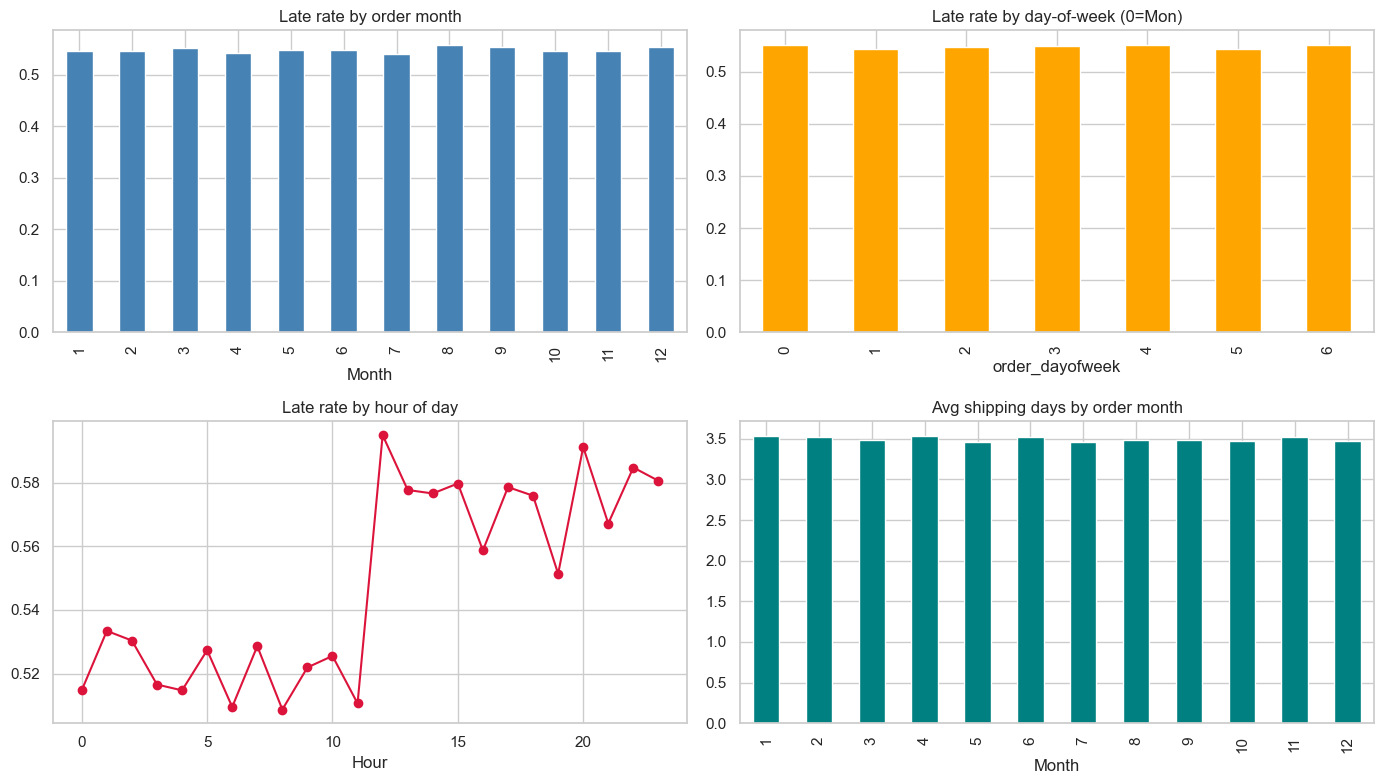

In [3]:
TARGET_SHIPPING = "Days for shipping (real)"
TARGET_LATE = "Late_delivery_risk"

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

df.groupby("order_month")[TARGET_LATE].mean().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Late rate by order month"); axes[0, 0].set_xlabel("Month")

df.groupby("order_dayofweek")[TARGET_LATE].mean().plot(kind="bar", ax=axes[0, 1], color="orange")
axes[0, 1].set_title("Late rate by day-of-week (0=Mon)")

df.groupby("order_hour")[TARGET_LATE].mean().plot(ax=axes[1, 0], color="crimson", marker="o")
axes[1, 0].set_title("Late rate by hour of day"); axes[1, 0].set_xlabel("Hour")

df.groupby("order_month")[TARGET_SHIPPING].mean().plot(kind="bar", ax=axes[1, 1], color="teal")
axes[1, 1].set_title("Avg shipping days by order month"); axes[1, 1].set_xlabel("Month")

plt.tight_layout()
plt.show()

## 2. Feature Lists per Task

Choose features that are realistically available **at order time** — anything that reveals the actual outcome (delivery status, shipping date) was already removed in preprocessing.

In [4]:
DATE_FEATURES = [
    "order_year", "order_month", "order_day",
    "order_dayofweek", "order_hour",
]

FEATURES_SHIPPING = [
    "Type",
    "Days for shipment (scheduled)",
    "Customer Country",
    "Customer Segment",
    "Market",
    "Order Country",
    "Order Region",
    "Shipping Mode",
    "Order Item Quantity",
    "Latitude",
    "Longitude",
]

FEATURES_LATE = [
    "Type",
    "Days for shipment (scheduled)",
    "Customer Country",
    "Customer Segment",
    "Market",
    "Order Country",
    "Order Region",
    "Shipping Mode",
    "Order Item Quantity",
    "Category Name",
    "Latitude",
    "Longitude",
] + DATE_FEATURES

print("Shipping features:", len(FEATURES_SHIPPING))
print("Late features:    ", len(FEATURES_LATE))

Shipping features: 11
Late features:     17


## 3. Label Encoding

Tree-based models (Random Forest, XGBoost, Gradient Boosting) handle integer-encoded categoricals well, and label encoding keeps the feature matrix narrow even with high-cardinality columns like `Order Country`.

In [5]:
df_encoded = df.copy()
categorical_cols = df_encoded.select_dtypes(include=["object"]).columns.tolist()

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le

print("Encoded", len(categorical_cols), "categorical columns")
pd.Series({c: len(label_encoders[c].classes_) for c in categorical_cols}).sort_values(ascending=False).head(10)

Encoded 16 categorical columns


shipping date (DateOrders)    63701
Order City                     3597
Order State                    1089
Customer City                   563
Order Country                   164
Product Name                    118
Category Name                    50
Customer State                   46
Order Region                     23
Department Name                  11
dtype: int64

## 4. Post-Encoding Feature/Target Diagnostics

Now that categoricals are numeric, refresh the correlation view restricted to the modelling features. This is what the model actually sees.

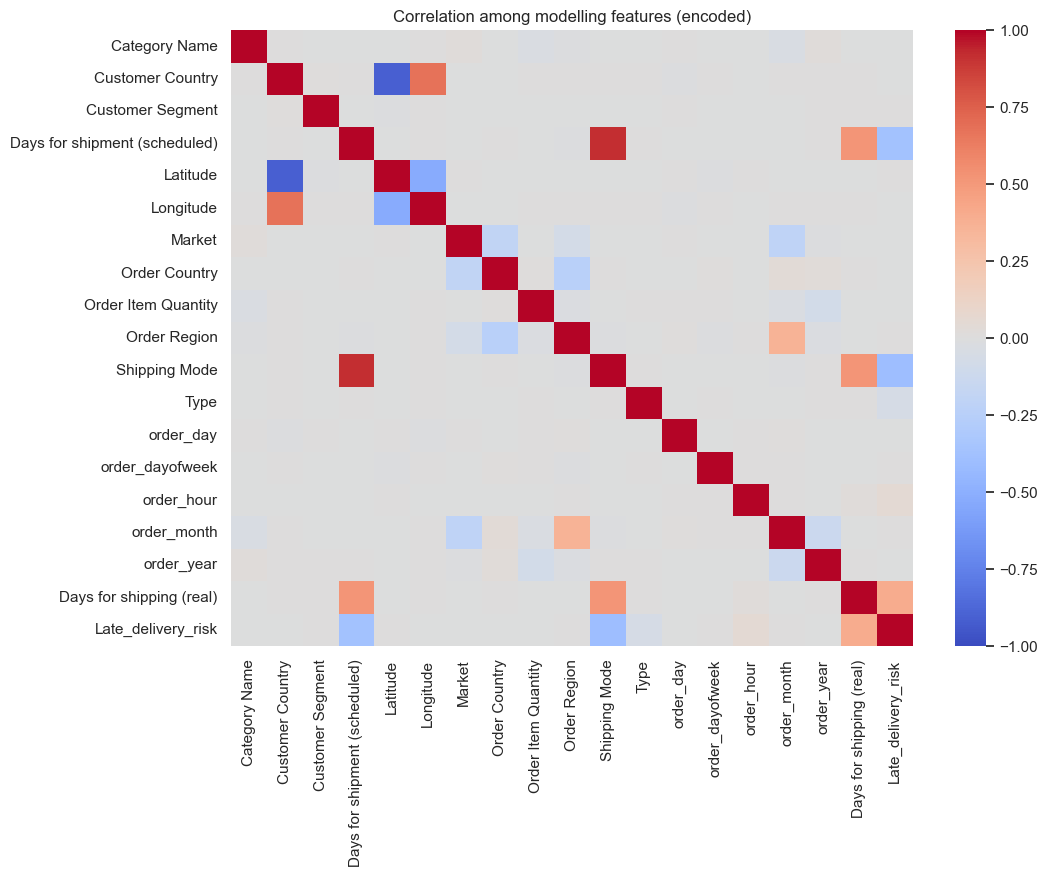

In [6]:
feat_cols = sorted(set(FEATURES_SHIPPING) | set(FEATURES_LATE))
corr_block = df_encoded[feat_cols + [TARGET_SHIPPING, TARGET_LATE]].corr()

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_block, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=False, ax=ax)
ax.set_title("Correlation among modelling features (encoded)")
plt.show()

In [7]:
# Top |corr| with each target, restricted to features actually used by the models
for tgt, feats in [(TARGET_SHIPPING, FEATURES_SHIPPING), (TARGET_LATE, FEATURES_LATE)]:
    s = corr_block.loc[feats, tgt].abs().sort_values(ascending=False)
    print(f"\nTop |corr| of features with {tgt}:")
    print(s.round(3).to_string())


Top |corr| of features with Days for shipping (real):
Days for shipment (scheduled)    0.516
Shipping Mode                    0.516
Type                             0.005
Latitude                         0.004
Longitude                        0.004
Order Region                     0.004
Customer Country                 0.003
Customer Segment                 0.002
Order Country                    0.002
Market                           0.001
Order Item Quantity              0.001

Top |corr| of features with Late_delivery_risk:
Shipping Mode                    0.401
Days for shipment (scheduled)    0.369
Type                             0.062
order_hour                       0.047
Order Region                     0.006
order_month                      0.003
order_year                       0.002
order_day                        0.002
Longitude                        0.002
Order Country                    0.002
Customer Segment                 0.001
Category Name                    0.001

## 5. Build X / y

In [8]:
X_ship = df_encoded[FEATURES_SHIPPING].copy()
y_ship = df_encoded[TARGET_SHIPPING].copy()

X_late = df_encoded[FEATURES_LATE].copy()
y_late = df_encoded[TARGET_LATE].copy()

print("Shipping X:", X_ship.shape, " y:", y_ship.shape)
print("Late     X:", X_late.shape, " y:", y_late.shape)

Shipping X: (180519, 11)  y: (180519,)
Late     X: (180519, 17)  y: (180519,)


## 6. Train/Test Split

- Shipping (regression): random 80/20 split
- Late delivery (classification): stratified 80/20 split to preserve class balance

In [9]:
RANDOM_STATE = 42
TEST_SIZE = 0.2

X_train_ship, X_test_ship, y_train_ship, y_test_ship = train_test_split(
    X_ship, y_ship, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

X_train_late, X_test_late, y_train_late, y_test_late = train_test_split(
    X_late, y_late, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_late
)

print("Shipping  train/test:", X_train_ship.shape, X_test_ship.shape)
print("Late      train/test:", X_train_late.shape, X_test_late.shape)
print("Late train class balance:", y_train_late.value_counts(normalize=True).round(3).to_dict())
print("Late test  class balance:", y_test_late.value_counts(normalize=True).round(3).to_dict())

Shipping  train/test: (144415, 11) (36104, 11)
Late      train/test: (144415, 17) (36104, 17)
Late train class balance: {1: 0.548, 0: 0.452}
Late test  class balance: {1: 0.548, 0: 0.452}


## 7. Persist Splits

In [10]:
os.makedirs("../data/preprocessed", exist_ok=True)

X_train_ship.to_csv("../data/preprocessed/X_train_ship.csv", index=False)
X_test_ship.to_csv("../data/preprocessed/X_test_ship.csv", index=False)
y_train_ship.to_csv("../data/preprocessed/y_train_ship.csv", index=False)
y_test_ship.to_csv("../data/preprocessed/y_test_ship.csv", index=False)

X_train_late.to_csv("../data/preprocessed/X_train_late.csv", index=False)
X_test_late.to_csv("../data/preprocessed/X_test_late.csv", index=False)
y_train_late.to_csv("../data/preprocessed/y_train_late.csv", index=False)
y_test_late.to_csv("../data/preprocessed/y_test_late.csv", index=False)

print("Saved train/test splits to ../data/preprocessed/")

Saved train/test splits to ../data/preprocessed/
